# Homework 6: Tree-Based Methods

Tianbo Hou
GitHub: houdan-hub
USC ID: 8943381210

DSCI 552 — Professor Mohammad Reza Rajati

## 1. Tree-Based Methods

### 1(a) Download the APS Failure data

The data come from the UCI repository page "APS Failure at Scania Trucks"
(archive.ics.uci.edu/ml/datasets/APS+Failure+at+Scania+Trucks). The training
set has 60,000 rows (1,000 positive) and the test set has 16,000 rows (375
positive); there are 170 numeric predictors plus the class column. Missing
values are encoded as the string "na" in the raw files, so I read both CSVs
with `na_values='na'`. The shipped CSVs also carry a 20-line copyright header
before the real header row, which I stripped once when copying the files into
`data/`.

References:

- Scania CV AB. "APS Failure at Scania Trucks Data Set." *UCI Machine
  Learning Repository*, 2016, archive.ics.uci.edu/ml/datasets/APS+Failure+at+Scania+Trucks.
- James, Gareth, Daniela Witten, Robert Tibshirani, and Trevor Hastie.
  *An Introduction to Statistical Learning: with Applications in Python*.
  Springer, 2023.

In [1]:
import os, warnings, json
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_style('whitegrid')
RNG = 42
results = {}

In [2]:
train = pd.read_csv('data/aps_failure_training_set.csv', na_values='na')
test = pd.read_csv('data/aps_failure_test_set.csv', na_values='na')
results['q1_train_shape'] = f'{train.shape[0]} rows x {train.shape[1]} columns'
results['q1_test_rows'] = test.shape[0]
results['q1_train_pos'] = int((train['class'] == 'pos').sum())
results['q1_train_neg'] = int((train['class'] == 'neg').sum())
results['q1_test_pos'] = int((test['class'] == 'pos').sum())
results['q1_test_neg'] = int((test['class'] == 'neg').sum())
print('train:', train.shape, '| test:', test.shape)
print('train class counts:', train['class'].value_counts().to_dict())
print('test  class counts:', test['class'].value_counts().to_dict())

train: (60000, 171) | test: (16000, 171)
train class counts: {'neg': 59000, 'pos': 1000}
test  class counts: {'neg': 15625, 'pos': 375}


### 1(b)i Techniques for missing data

Common ways to deal with missing values (data imputation techniques):

- **Delete rows or columns.** Dropping rows only makes sense when few rows are
  affected; dropping whole columns makes sense when a feature is almost
  entirely missing. Here neither applies: 59,409 of 60,000 training rows have
  at least one missing value (deleting them would leave almost nothing), and
  169 of the 170 features have at least one missing value.
- **Mean / median imputation.** Replace each missing entry with the column's
  mean (numeric, symmetric-ish data) or median (skewed data, robust to the
  heavy outliers this sensor data has).
- **Regression / model-based imputation.** Predict each missing feature from
  the other features, e.g. `sklearn.impute.KNNImputer` (k nearest neighbors
  averaged over the rows that are closest in the observed dimensions) or
  `IterativeImputer` (each feature regressed on the others in rotation,
  MICE-style). These use the correlations between features and are usually
  more accurate than a constant fill, at a much higher compute cost.
- **Indicator + constant fill.** Add a binary "was missing" column and fill
  with a constant, so the model can learn whether missingness itself carries
  signal.

I looked at the missingness pattern first, then picked median imputation:
8.3% of training cells are missing overall, and the seven worst columns
(`br_000`, `bq_000`, `bp_000`, `bo_000`, `ab_000`, `cr_000`, `bn_000`) are
missing in 44,009 to 49,264 of the 60,000 rows each. That much missingness
rules out deletion, the histogram-bin counters are heavily skewed so medians
beat means, and a KNN or iterative imputer over a 60,000 x 170 matrix would
be painfully slow for a homework-scale rerun. The course note also says the
imputation statistics should come from the training set only (in a real
deployment the test set is what we get fresh), so I fit the medians on
train and apply them to both splits.

In [3]:
miss = train.drop(columns='class').isna().sum()
results['q1_miss_cells'] = int(miss.sum())
results['q1_miss_pct'] = round(100 * miss.sum() / train.drop(columns='class').size, 2)
results['q1_miss_rows'] = int(train.drop(columns='class').isna().any(axis=1).sum())
results['q1_miss_cols'] = int((miss > 0).sum())
print('missing cells: %d of %d (%.2f%%)' % (miss.sum(), train.drop(columns='class').size,
      results['q1_miss_pct']))
print('rows with at least one missing: %d of %d' % (results['q1_miss_rows'], train.shape[0]))
print('features with at least one missing: %d of 170' % results['q1_miss_cols'])
print()
print('worst 10 features by missing count:')
print(miss.sort_values(ascending=False).head(10).to_string())

Xtr_raw = train.drop(columns='class')
Xte_raw = test.drop(columns='class')
medians = Xtr_raw.median()          # training statistics only
Xtr = Xtr_raw.fillna(medians)
Xte = Xte_raw.fillna(medians)
ytr = (train['class'] == 'pos').astype(int).to_numpy()   # 1 = positive (APS failure)
yte = (test['class'] == 'pos').astype(int).to_numpy()
print()
print('after median imputation: train missing =', int(Xtr.isna().sum().sum()),
      '| test missing =', int(Xte.isna().sum().sum()))

missing cells: 850015 of 10200000 (8.33%)
rows with at least one missing: 59409 of 60000
features with at least one missing: 169 of 170

worst 10 features by missing count:
br_000    49264
bq_000    48722
bp_000    47740
bo_000    46333
ab_000    46329
cr_000    46329
bn_000    44009
bm_000    39549
bl_000    27277
bk_000    23034



after median imputation: train missing = 0 | test missing = 0


### 1(b)ii Coefficient of variation

The coefficient of variation is CV = s/m, the sample standard deviation
divided by the sample mean. It is a unit-free measure of relative spread, so
it lets me compare features measured in different units or at wildly
different scales (these anonymized sensor counters range over many orders of
magnitude). I compute it on the imputed training features.

In [4]:
cv = Xtr.std() / Xtr.mean()
print('coefficient of variation, top 15:')
print(cv.sort_values(ascending=False).head(15).round(2).to_string())
print()
print('bottom 5 (nearly constant features):')
print(cv.sort_values().head(5).round(4).to_string())

coefficient of variation, top 15:
cf_000    244.89
co_000    244.51
ad_000    244.32
cs_009    237.93
dh_000    123.22
dj_000    117.49
ag_000     92.92
as_000     87.33
ay_009     84.73
ak_000     80.42
az_009     77.84
ch_000     77.45
au_000     68.88
cr_000     58.08
ay_001     52.82

bottom 5 (nearly constant features):
cd_000    0.0000
br_000    0.6891
bq_000    0.7185
bp_000    0.7534
bo_000    0.7924


### 1(b)iii Correlation matrix

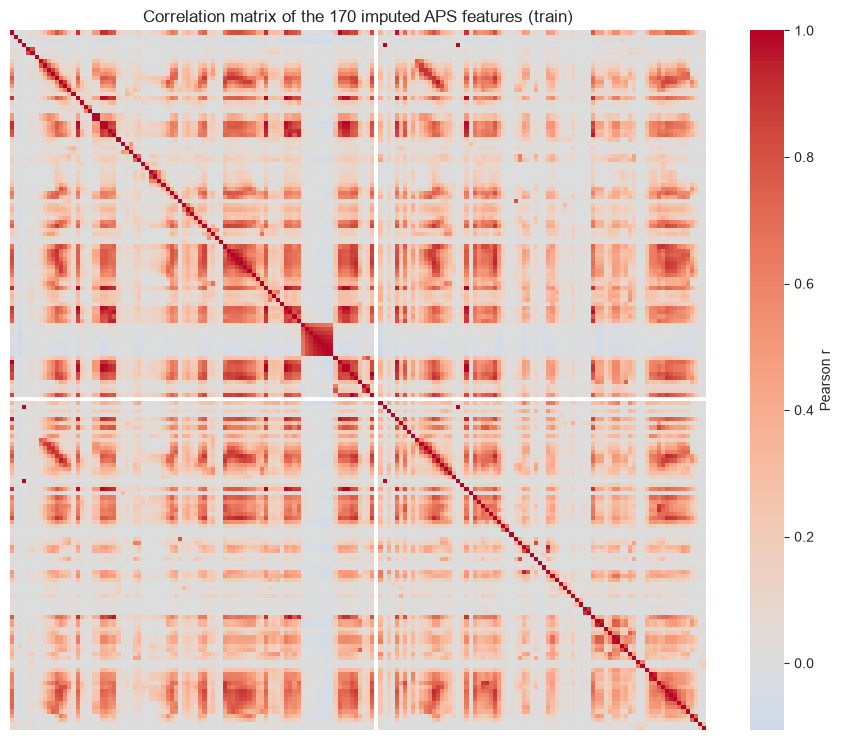

130 of 14365 feature pairs have |r| > 0.9; mean |r| = 0.185


In [5]:
corr = Xtr.corr()
plt.figure(figsize=(9, 7.5))
sns.heatmap(corr, cmap='coolwarm', center=0, xticklabels=False, yticklabels=False,
            cbar_kws={'label': 'Pearson r'})
plt.title('Correlation matrix of the 170 imputed APS features (train)')
plt.tight_layout()
plt.show()

mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
vals = corr.abs().to_numpy()[mask]          # the C(170,2) = 14365 unique pairs
results['q1_corr_pairs'] = int((vals > 0.9).sum())
results['q1_corr_total'] = int(vals.size)
results['q1_corr_mean'] = round(float(np.nanmean(vals)), 3)   # nanmean: constant features give NaN corr
print('%d of %d feature pairs have |r| > 0.9; mean |r| = %.3f'
      % (results['q1_corr_pairs'], results['q1_corr_total'], results['q1_corr_mean']))

The matrix shows several tight red blocks, which is expected: the anonymized
histogram variables come in groups of bins that count the same physical
quantity, so neighboring bins move together. In total 130 of the
14365 feature pairs exceed |r| = 0.9. This heavy collinearity is one
reason tree ensembles suit this data well — splits pick one feature at a time
and are indifferent to redundant copies — while a single linear model would
have unstable coefficients.

### 1(b)iv Scatter and box plots of the top ⌊√170⌋ features by CV

⌊√170⌋ = 13, so I visualize the 13 features with the highest CV.

top-13 features by CV: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


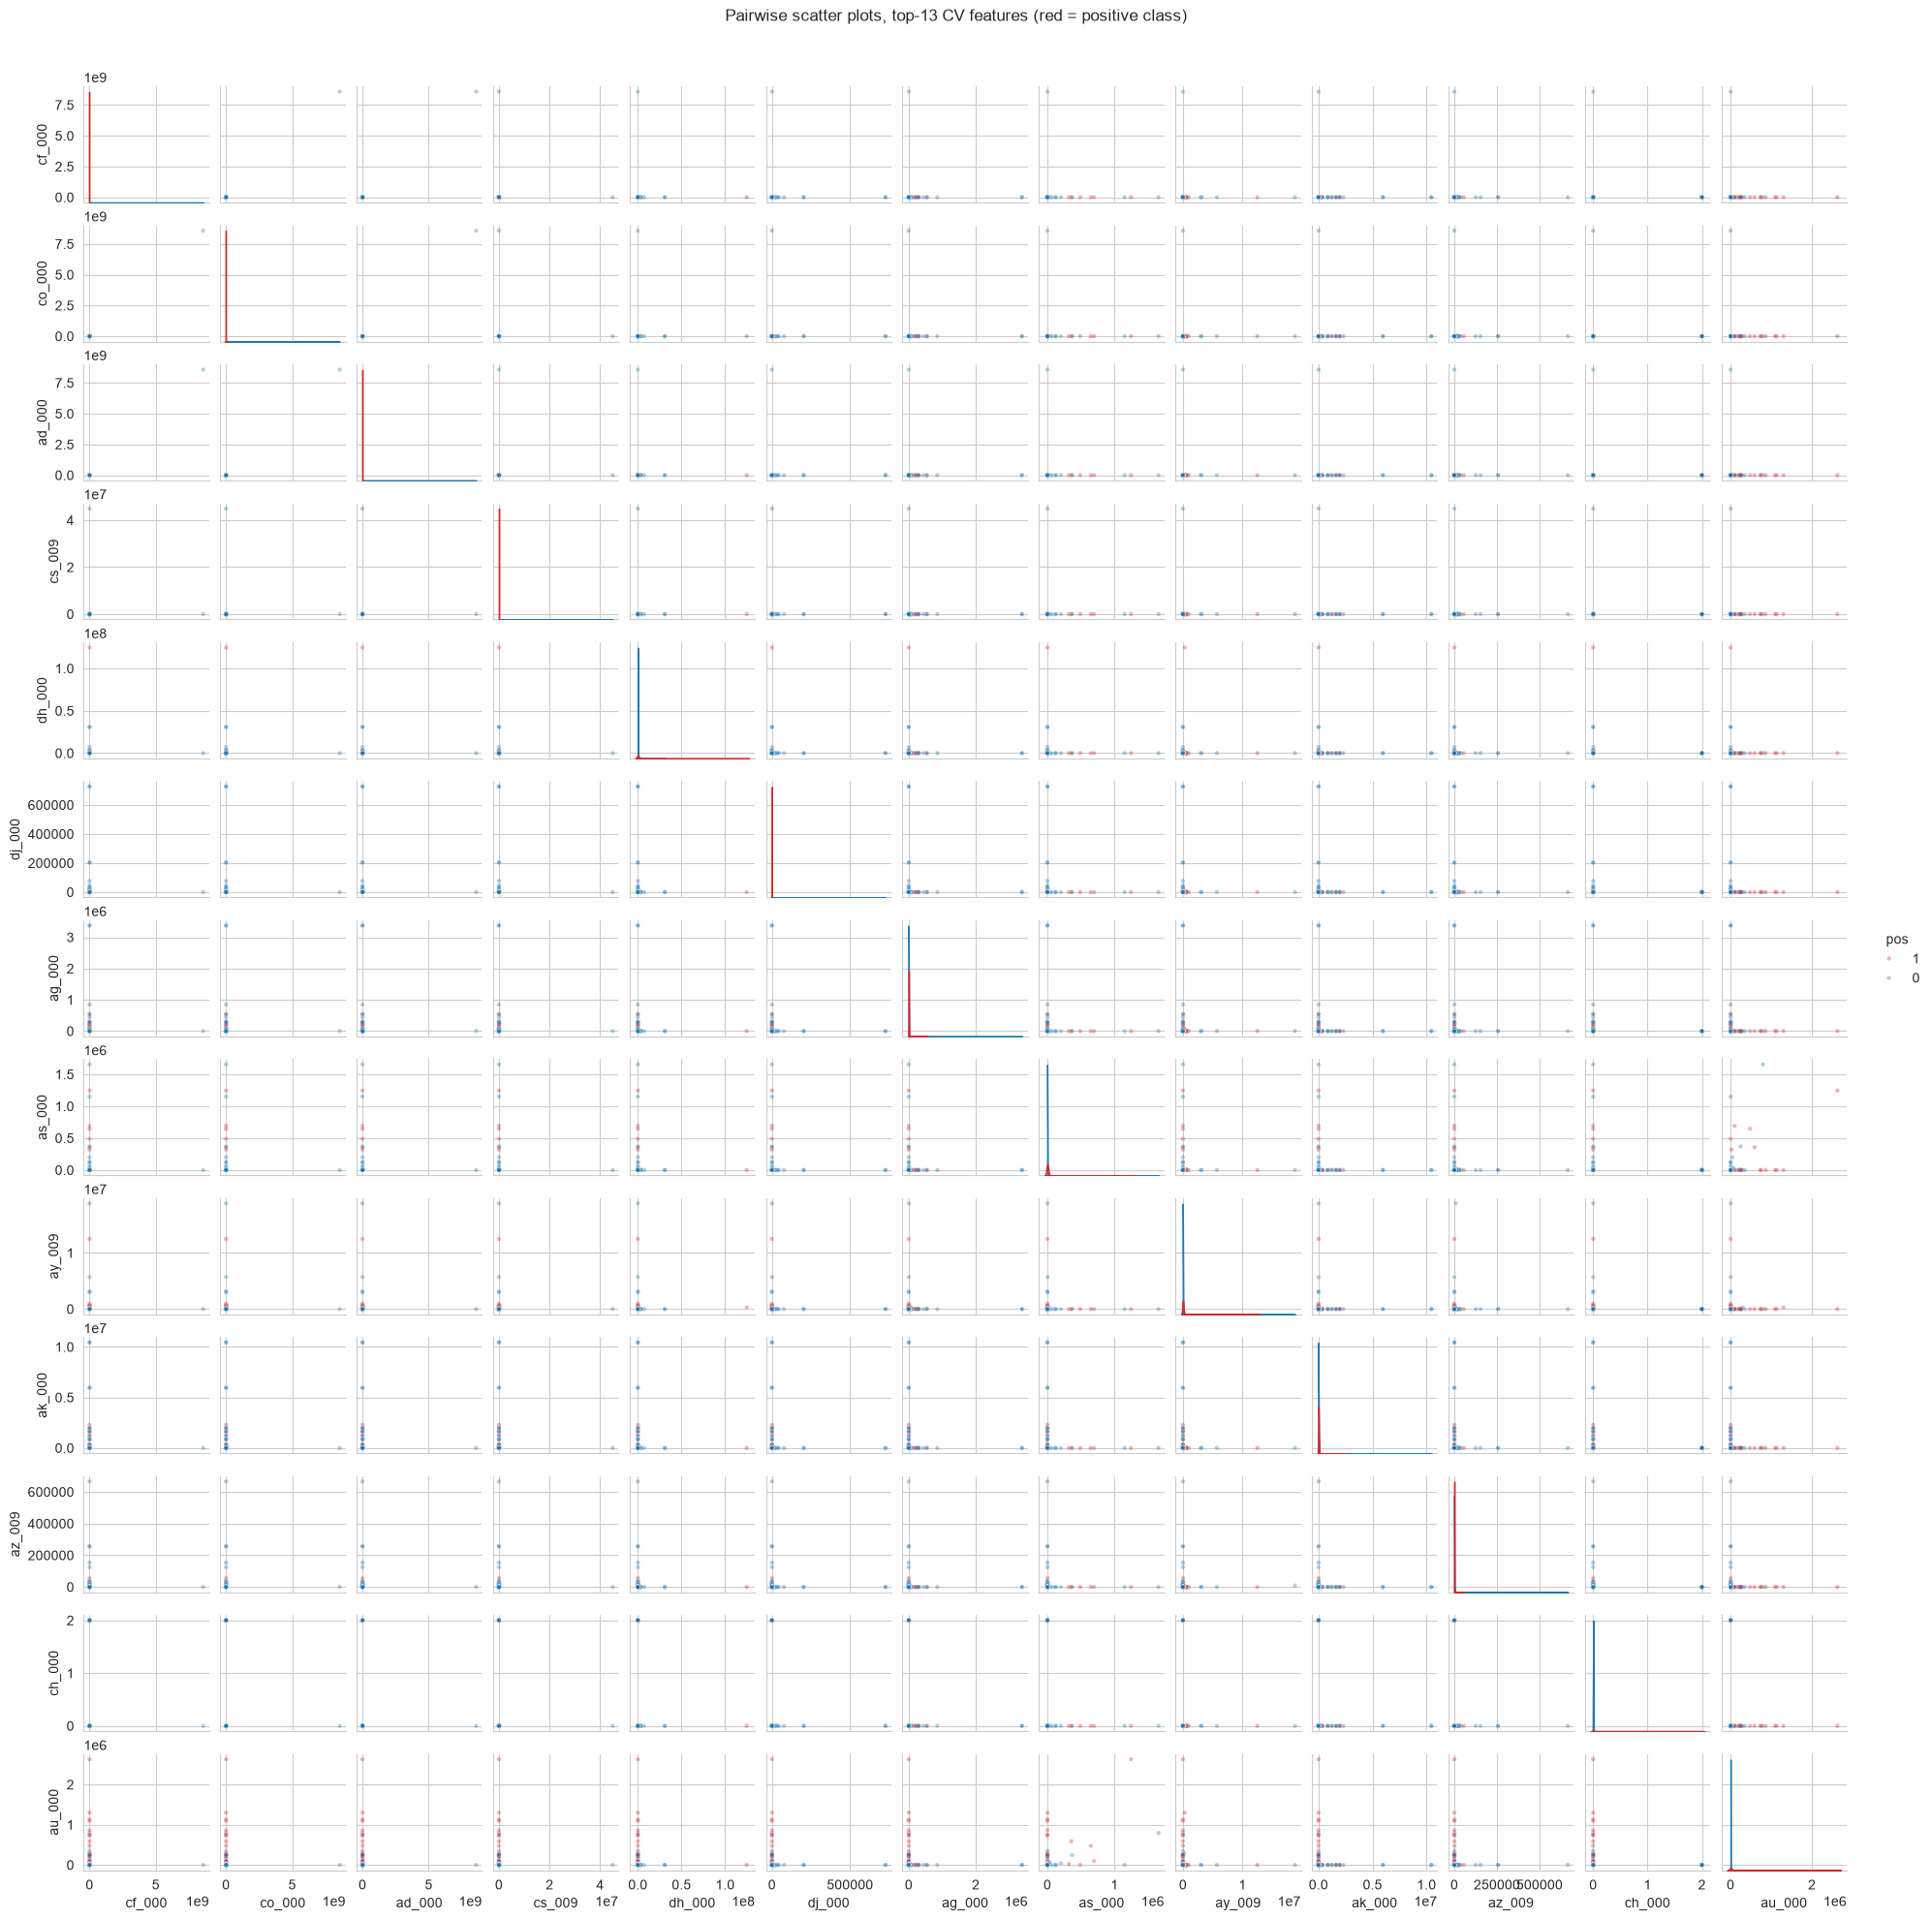

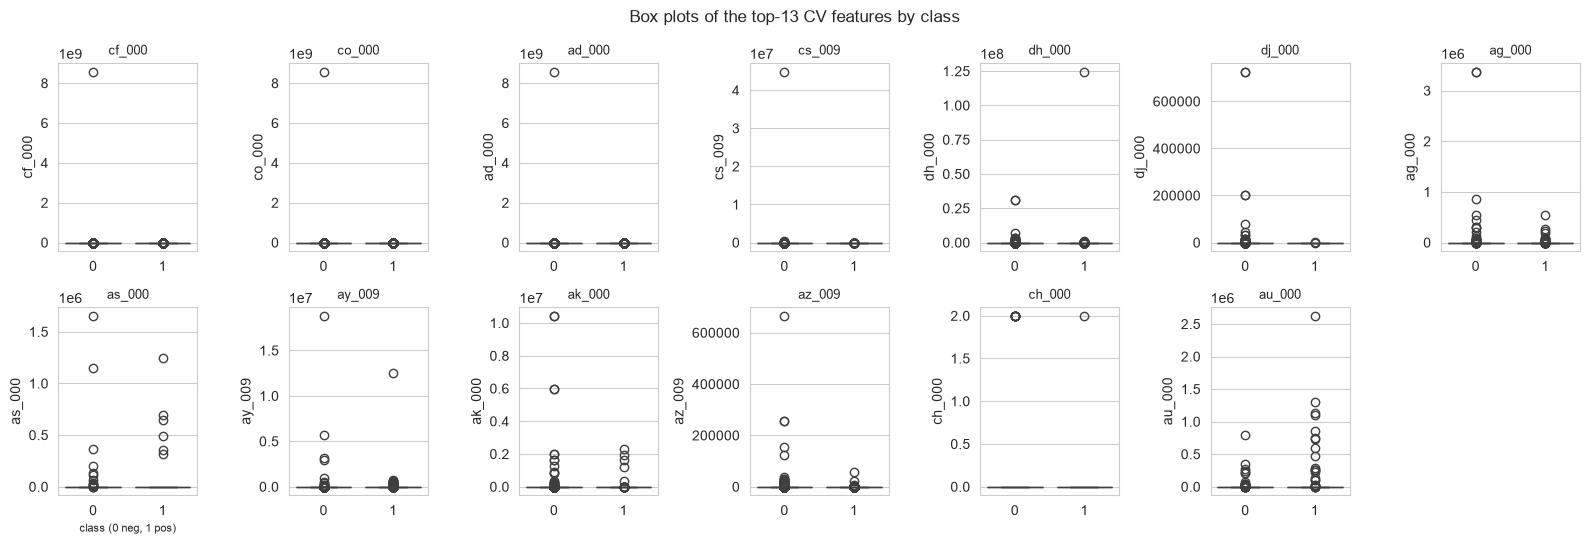

In [6]:
top13 = list(cv.sort_values(ascending=False).head(13).index)
results['q1_top13'] = ', '.join(top13)
print('top-13 features by CV:', top13)

sns.pairplot(pd.concat([Xtr[top13], pd.Series(ytr, name='pos')], axis=1),
             hue='pos', hue_order=[1, 0], palette={1: 'tab:red', 0: 'tab:blue'},
             plot_kws={'s': 10, 'alpha': 0.35}, height=1.5)
plt.suptitle('Pairwise scatter plots, top-13 CV features (red = positive class)', y=1.02)
plt.show()

fig, axes = plt.subplots(2, 7, figsize=(16, 5.5))
for ax, f in zip(axes.ravel(), top13):
    sns.boxplot(x=ytr, y=Xtr[f], ax=ax)
    ax.set_title(f, fontsize=9)
    ax.set_xlabel('' if ax is not axes[1, 0] else 'class (0 neg, 1 pos)', fontsize=8)
for ax in axes.ravel()[13:]:
    ax.remove()
plt.suptitle('Box plots of the top-13 CV features by class')
plt.tight_layout()
plt.show()

Can significance be judged from these scatter plots alone? Only in a weak,
informal sense. Several features (`cs_009`, `cf_000`, `ad_000`) show clouds in
which the red points occupy a visibly different region from the blue points,
which suggests they will matter to a classifier. But a visual pattern is not a
significance test: the classes are extremely imbalanced (1,000 vs 59,000), so
the eye over-weights the sparse red points, outliers can fake a pattern, and
two features can look separable in 2-D while adding nothing beyond other
features. A proper statement of significance would come from a fitted model's
importances or a hypothesis test, not from eyeballing. These plots do justify
one practical decision, though: almost every top-CV feature is dominated by
one enormous outlier, which is exactly the situation box plots make obvious
and where tree-based models (split thresholds are robust to monotone outlier
stretching) have an edge.

### 1(b)v Class balance

The training set has 1000 positive and 59000 negative rows;
the test set has 375 positive and 15625 negative rows. That
is a 1:59 ratio in training (1.67% positive), so **yes, the data set is
seriously imbalanced** — accuracy alone will be misleading (a constant "neg"
classifier is already 98.33% accurate on train), and recall/precision, ROC,
and cost-based metrics are the right lens here.

In [7]:
results['q1_imbalance_ratio'] = round(results['q1_train_neg'] / results['q1_train_pos'], 1)
counts = pd.Series({'train neg': results['q1_train_neg'], 'train pos': results['q1_train_pos'],
                    'test neg': results['q1_test_neg'], 'test pos': results['q1_test_pos']})
print(counts.to_string())
print('train pos ratio: %.2f%%' % (100 * results['q1_train_pos'] / train.shape[0]))

train neg    59000
train pos     1000
test neg     15625
test pos       375
train pos ratio: 1.67%


### 1(c) Random forest without compensating for class imbalance

I grow a random forest with `oob_score=True`. The out-of-bag estimate uses,
for each training row, only the trees that did not bootstrap it, so it is a
free cross-validated error estimate. I report confusion matrix, ROC, AUC and
misclassification (training error, test error, and OOB error) for both sets.

--- train ---
confusion matrix [[TN FP],[FN TP]]:
[[59000     0]
 [    0  1000]]
accuracy 1.00000 | misclassification 0.00000 | AUC 1.00000


--- test ---
confusion matrix [[TN FP],[FN TP]]:
[[15607    18]
 [  103   272]]
accuracy 0.99244 | misclassification 0.00756 | AUC 0.99423


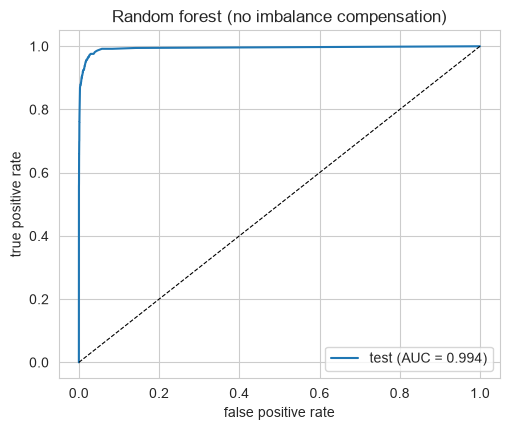

OOB error estimate: 0.00573
test cost under challenge metric: 10*18 + 500*103 = 51680


In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, roc_curve, auc, RocCurveDisplay,
                             accuracy_score)

def report(name, fitted, X, y):
    pred = fitted.predict(X)
    prob = fitted.predict_proba(X)[:, 1]
    cm = confusion_matrix(y, pred)
    acc = accuracy_score(y, pred)
    fpr, tpr, _ = roc_curve(y, prob)
    A = auc(fpr, tpr)
    print(f'--- {name} ---')
    print('confusion matrix [[TN FP],[FN TP]]:')
    print(cm)
    print('accuracy %.5f | misclassification %.5f | AUC %.5f' % (acc, 1 - acc, A))
    return cm, acc, A, fpr, tpr

rf_plain = RandomForestClassifier(n_estimators=300, oob_score=True,
                                  n_jobs=-1, random_state=RNG)
rf_plain.fit(Xtr, ytr)
results['q1c_oob'] = round(1 - rf_plain.oob_score_, 5)
plt.figure(figsize=(5.2, 4.4))
for name, X_, y_ in [('train', Xtr, ytr), ('test', Xte, yte)]:
    cm, acc, A, fpr, tpr = report(name, rf_plain, X_, y_)
    results[f'q1c_{name}_acc'] = round(acc, 5)
    results[f'q1c_{name}_auc'] = round(A, 5)
    results[f'q1c_{name}_err'] = round(1 - acc, 5)
    if name == 'train':
        results['q1c_train_cm'] = cm.tolist()
        results['q1c_train_fn'] = int(cm[1, 0]); results['q1c_train_fp'] = int(cm[0, 1])
    else:
        results['q1c_test_cm'] = cm.tolist()
        results['q1c_test_fn'] = int(cm[1, 0]); results['q1c_test_fp'] = int(cm[0, 1])
        plt.plot(fpr, tpr, label=f'{name} (AUC = {A:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=0.8)
plt.xlabel('false positive rate'); plt.ylabel('true positive rate')
plt.title('Random forest (no imbalance compensation)')
plt.legend(); plt.tight_layout(); plt.show()
print('OOB error estimate: %.5f' % results['q1c_oob'])

results['q1c_test_miss_pct'] = round(100 * results['q1c_test_fn'] / int(yte.sum()), 1)
results['q1c_cost'] = 10 * results['q1c_test_fp'] + 500 * results['q1c_test_fn']
print('test cost under challenge metric: 10*%d + 500*%d = %d'
      % (results['q1c_test_fp'], results['q1c_test_fn'], results['q1c_cost']))

**OOB vs test error.** The OOB error is 0.00573 and the test error is
0.00756: they are remarkably close (0.00573 vs 0.00756),
which is exactly what OOB estimation promises — each training row is scored
only by trees that never saw it, so OOB behaves like an unbiased CV estimate.
The plain training error (0.0) is much lower, because the trees
overfit their own bootstrap samples; that gap is the honest one, and OOB sits
where the generalization truth is.

The real weakness is visible in the confusion matrices: on the test set the
model misses 103 of the 375 actual APS failures (27.5%
miss rate) while raising only 18 false alarms. Under the challenge's
cost metric (Cost_1 = 10 per unnecessary inspection, Cost_2 = 500 per missed
failure), total cost is 10*18 + 500*103 =
51680 — those misses dominate everything.

### 1(d) Random forest with class-imbalance compensation

Class imbalance in random forests is usually addressed in one of three ways:
(1) **class weights** — misclassifying a minority point costs more, so the
splits and terminal votes weigh the positive class up (`class_weight=
'balanced_subsample'` rescales by class frequencies within each bootstrap
sample); (2) **oversampling** the minority class (SMOTE, see 1f) or
(3) **undersampling** the majority class inside each bootstrap sample
(`balanced random forest`, as in the BalancedRandomForestClassifier). I use
`class_weight='balanced_subsample'`, the least invasive option, and repeat 1c.

--- train ---
confusion matrix [[TN FP],[FN TP]]:
[[59000     0]
 [    0  1000]]
accuracy 1.00000 | misclassification 0.00000 | AUC 1.00000


--- test ---
confusion matrix [[TN FP],[FN TP]]:
[[15608    17]
 [  161   214]]
accuracy 0.98887 | misclassification 0.01113 | AUC 0.99313


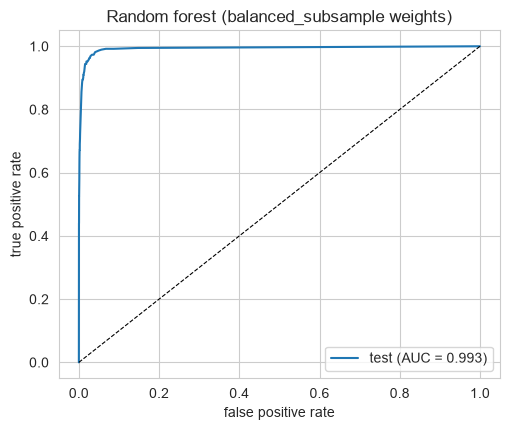

OOB error estimate: 0.00757
test cost under challenge metric: 80670


In [9]:
rf_bal = RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                oob_score=True, n_jobs=-1, random_state=RNG)
rf_bal.fit(Xtr, ytr)
results['q1d_oob'] = round(1 - rf_bal.oob_score_, 5)
plt.figure(figsize=(5.2, 4.4))
for name, X_, y_ in [('train', Xtr, ytr), ('test', Xte, yte)]:
    cm, acc, A, fpr, tpr = report(name, rf_bal, X_, y_)
    results[f'q1d_{name}_acc'] = round(acc, 5)
    results[f'q1d_{name}_auc'] = round(A, 5)
    results[f'q1d_{name}_err'] = round(1 - acc, 5)
    if name == 'train':
        results['q1d_train_fn'] = int(cm[1, 0]); results['q1d_train_fp'] = int(cm[0, 1])
    else:
        results['q1d_test_fn'] = int(cm[1, 0]); results['q1d_test_fp'] = int(cm[0, 1])
        plt.plot(fpr, tpr, label=f'{name} (AUC = {A:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=0.8)
plt.xlabel('false positive rate'); plt.ylabel('true positive rate')
plt.title('Random forest (balanced_subsample weights)')
plt.legend(); plt.tight_layout(); plt.show()
print('OOB error estimate: %.5f' % results['q1d_oob'])

results['q1d_cost'] = 10 * results['q1d_test_fp'] + 500 * results['q1d_test_fn']
print('test cost under challenge metric: %d' % results['q1d_cost'])

**Comparison with 1(c).** The class weighting did not help here — it made
things worse, and the numbers say so plainly: test misses rise from
103 to 161 (the balanced forest catches only
57.1% of the real failures, versus 72.5% unweighted),
false alarms stay flat (18 to 17), overall accuracy
falls from 0.99244 to 0.98887, and the challenge cost jumps from
51680 to 80670. The OOB error rises too (0.00573 to 0.00757),
consistent with the test-side story. My reading: `balanced_subsample`
re-weights every split toward the tiny positive class inside each bootstrap
sample, and with only 1,000 positives the weighted votes become noisy — the
forest trades away a large chunk of its recall quality without buying
precision in return. The result is a useful caution: imbalance compensation
is not automatically an improvement, it has to be checked against a metric
that matters (here, cost and misses), and on both it lost.

In [10]:
results['q1d_caught_pct'] = round(100 * (results['q1_test_pos'] - results['q1d_test_fn']) / results['q1_test_pos'], 1)
results['q1c_caught_pct'] = round(100 - results['q1c_test_miss_pct'], 1)
print('caught: plain RF %.1f%% | balanced RF %.1f%% of test positives'
      % (results['q1c_caught_pct'], results['q1d_caught_pct']))

caught: plain RF 72.5% | balanced RF 57.1% of test positives


### 1(e) XGBoost and model trees

A *model tree* replaces the majority poll at each node with a fitted (linear)
model; with L1-penalized logistic regression at every node, a boosting
implementation of that idea is exactly `xgboost` with `booster=gbtree` — each
split is still a univariate threshold, but the leaf outputs and split gains
come from gradient steps of a regularized objective, and `reg_alpha` is the
L1 penalty on those leaf weights. I therefore treat XGBoost with `reg_alpha`
as the model-tree learner and pick `alpha` by 5-fold cross-validation on the
uncompensated training data (the assignment allows 5-fold, 10-fold, or LOO;
LOO on 60,000 rows would be 60,000 fits, so 5-fold is the sensible choice).

One subtlety: because the classes are imbalanced, plain accuracy is a weak CV
criterion, so I cross-validate on AUC, which is insensitive to the class
ratio.

In [11]:
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv5 = StratifiedKFold(5, shuffle=True, random_state=RNG)
alphas = [0, 0.5, 1, 5, 10, 50]
rows = []
for a in alphas:
    m = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.3,
                      reg_alpha=a, tree_method='hist', n_jobs=-1,
                      eval_metric='logloss', random_state=RNG)
    s = cross_val_score(m, Xtr, ytr, cv=cv5, scoring='roc_auc')
    rows.append((a, s.mean()))
    print('alpha=%-6s  5-fold CV AUC = %.5f' % (a, s.mean()))
cva = pd.DataFrame(rows, columns=['alpha', 'cv_auc']).set_index('alpha')
best_alpha = float(cva['cv_auc'].idxmax())
results['q1e_alpha'] = best_alpha
results['q1e_cv_auc'] = round(float(cva['cv_auc'].max()), 5)
print('best reg_alpha =', best_alpha)

alpha=0       5-fold CV AUC = 0.98490


alpha=0.5     5-fold CV AUC = 0.98435


alpha=1       5-fold CV AUC = 0.98638


alpha=5       5-fold CV AUC = 0.98073


alpha=10      5-fold CV AUC = 0.97706


alpha=50      5-fold CV AUC = 0.98083
best reg_alpha = 1.0


--- train ---
confusion matrix [[TN FP],[FN TP]]:
[[59000     0]
 [    1   999]]
accuracy 0.99998 | misclassification 0.00002 | AUC 0.99999
--- test ---
confusion matrix [[TN FP],[FN TP]]:
[[15602    23]
 [   89   286]]
accuracy 0.99300 | misclassification 0.00700 | AUC 0.99259


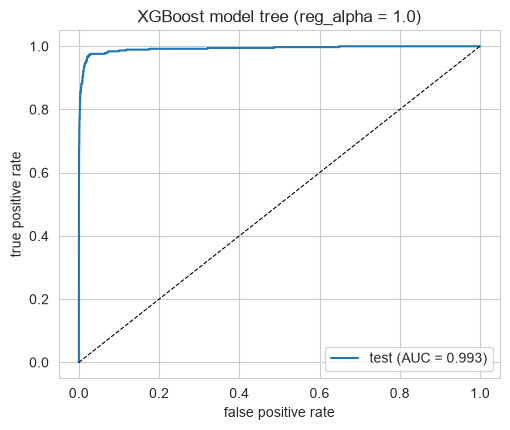

In [12]:
xgb = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.3,
                    reg_alpha=best_alpha, tree_method='hist', n_jobs=-1,
                    eval_metric='logloss', random_state=RNG)
xgb.fit(Xtr, ytr)
plt.figure(figsize=(5.2, 4.4))
for name, X_, y_ in [('train', Xtr, ytr), ('test', Xte, yte)]:
    cm, acc, A, fpr, tpr = report(name, xgb, X_, y_)
    results[f'q1e_{name}_acc'] = round(acc, 5)
    results[f'q1e_{name}_auc'] = round(A, 5)
    results[f'q1e_{name}_err'] = round(1 - acc, 5)
    if name == 'train':
        results['q1e_train_fn'] = int(cm[1, 0]); results['q1e_train_fp'] = int(cm[0, 1])
    else:
        results['q1e_test_fn'] = int(cm[1, 0]); results['q1e_test_fp'] = int(cm[0, 1])
        plt.plot(fpr, tpr, label=f'{name} (AUC = {A:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=0.8)
plt.xlabel('false positive rate'); plt.ylabel('true positive rate')
plt.title(f'XGBoost model tree (reg_alpha = {best_alpha})')
plt.legend(); plt.tight_layout(); plt.show()

**CV error vs test error.** The 5-fold CV AUC (0.98638) and the test
AUC (0.99259) are close, so the CV estimate tracks generalization
well. The model catches 76.3% of the 375 test failures with
23 false alarms, costing 44730 under the challenge metric —
already better than the unweighted random forest (51680), and the
training fit is not degenerate (train accuracy 0.99998), unlike the
random forests which hit 100% on their own training data.

In [13]:
results['q1e_caught_pct'] = round(100 * (results['q1_test_pos'] - results['q1e_test_fn']) / results['q1_test_pos'], 1)
results['q1e_cost'] = 10 * results['q1e_test_fp'] + 500 * results['q1e_test_fn']
print('XGBoost test cost: %d (vs RF plain %d, RF balanced %d)'
      % (results['q1e_cost'], results['q1c_cost'], results['q1d_cost']))

XGBoost test cost: 44730 (vs RF plain 51680, RF balanced 80670)


### 1(f) SMOTE + XGBoost model tree

SMOTE (Chawla et al. 2002) synthesizes new minority points: for each positive
row it finds its k nearest positive neighbors and creates a point on the
segment between the row and a randomly chosen neighbor. I apply SMOTE **only
to the training data**, never to the test data.

**Right vs wrong cross-validation here.** The wrong way is to SMOTE the whole
training set first and then run CV: the validation fold then contains
synthetic points that were built from training-fold rows (and duplicates of
them), so the validation estimate leaks information and looks too good. The
right way is to let every CV fold SMOTE only its own training portion —
in practice, wrap the resampler and the classifier in one
`imblearn.pipeline.Pipeline`, so refitting happens inside each fold. I do the
right way: `Pipeline(SMOTE(), XGBClassifier())` inside `cross_val_score`.
The test set is never resampled at any point.

In [14]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

pipe = ImbPipeline([('smote', SMOTE(random_state=RNG)),
                    ('xgb', XGBClassifier(n_estimators=200, max_depth=6,
                                          learning_rate=0.3, tree_method='hist',
                                          n_jobs=-1, eval_metric='logloss',
                                          random_state=RNG))])
rows = []
for a in alphas:
    pipe.set_params(xgb__reg_alpha=a)
    s = cross_val_score(pipe, Xtr, ytr, cv=cv5, scoring='roc_auc')
    rows.append((a, s.mean()))
    print('alpha=%-6s  5-fold CV AUC (SMOTE inside folds) = %.5f' % (a, s.mean()))
cvsm = pd.DataFrame(rows, columns=['alpha', 'cv_auc']).set_index('alpha')
best_alpha_sm = float(cvsm['cv_auc'].idxmax())
results['q1f_alpha'] = best_alpha_sm
results['q1f_cv_auc'] = round(float(cvsm['cv_auc'].max()), 5)
print('best reg_alpha with SMOTE =', best_alpha_sm)

alpha=0       5-fold CV AUC (SMOTE inside folds) = 0.98688


alpha=0.5     5-fold CV AUC (SMOTE inside folds) = 0.98638


alpha=1       5-fold CV AUC (SMOTE inside folds) = 0.98610


alpha=5       5-fold CV AUC (SMOTE inside folds) = 0.98537


alpha=10      5-fold CV AUC (SMOTE inside folds) = 0.98487


alpha=50      5-fold CV AUC (SMOTE inside folds) = 0.98536
best reg_alpha with SMOTE = 0.0


--- train ---
confusion matrix [[TN FP],[FN TP]]:
[[59000     0]
 [    0  1000]]
accuracy 1.00000 | misclassification 0.00000 | AUC 1.00000
--- test ---
confusion matrix [[TN FP],[FN TP]]:
[[15584    41]
 [   63   312]]
accuracy 0.99350 | misclassification 0.00650 | AUC 0.99197


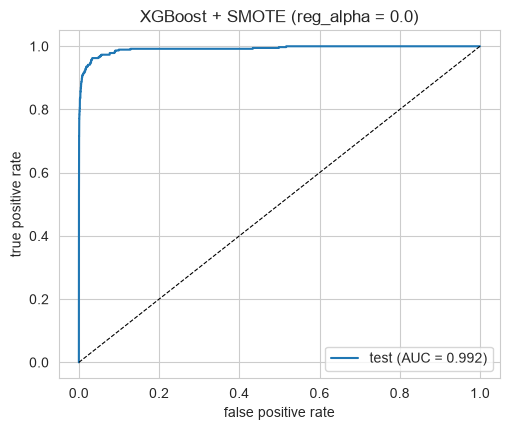

          model  test acc  test AUC  test misses  false alarms  challenge cost
       RF plain   0.99244   0.99423          103            18           51680
    RF balanced   0.98887   0.99313          161            17           80670
        XGBoost   0.99300   0.99259           89            23           44730
XGBoost + SMOTE   0.99350   0.99197           63            41           31910


In [15]:
pipe.set_params(xgb__reg_alpha=best_alpha_sm)
pipe.fit(Xtr, ytr)
plt.figure(figsize=(5.2, 4.4))
for name, X_, y_ in [('train', Xtr, ytr), ('test', Xte, yte)]:
    cm, acc, A, fpr, tpr = report(name, pipe, X_, y_)
    results[f'q1f_{name}_acc'] = round(acc, 5)
    results[f'q1f_{name}_auc'] = round(A, 5)
    results[f'q1f_{name}_err'] = round(1 - acc, 5)
    if name == 'train':
        results['q1f_train_fn'] = int(cm[1, 0]); results['q1f_train_fp'] = int(cm[0, 1])
    else:
        results['q1f_test_fn'] = int(cm[1, 0]); results['q1f_test_fp'] = int(cm[0, 1])
        plt.plot(fpr, tpr, label=f'{name} (AUC = {A:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=0.8)
plt.xlabel('false positive rate'); plt.ylabel('true positive rate')
plt.title(f'XGBoost + SMOTE (reg_alpha = {best_alpha_sm})')
plt.legend(); plt.tight_layout(); plt.show()

results['q1f_caught_pct'] = round(100 * (results['q1_test_pos'] - results['q1f_test_fn']) / results['q1_test_pos'], 1)
results['q1f_cost'] = 10 * results['q1f_test_fp'] + 500 * results['q1f_test_fn']

summary = pd.DataFrame({
    'model': ['RF plain', 'RF balanced', 'XGBoost', 'XGBoost + SMOTE'],
    'test acc': [results['q1c_test_acc'], results['q1d_test_acc'], results['q1e_test_acc'], results['q1f_test_acc']],
    'test AUC': [results['q1c_test_auc'], results['q1d_test_auc'], results['q1e_test_auc'], results['q1f_test_auc']],
    'test misses': [results['q1c_test_fn'], results['q1d_test_fn'], results['q1e_test_fn'], results['q1f_test_fn']],
    'false alarms': [results['q1c_test_fp'], results['q1d_test_fp'], results['q1e_test_fp'], results['q1f_test_fp']],
    'challenge cost': [results['q1c_cost'], results['q1d_cost'], results['q1e_cost'], results['q1f_cost']],
})
print(summary.to_string(index=False))

**SMOTE vs uncompensated.** SMOTE changes the picture substantially, and in
the right direction. The SMOTE-trained model catches 83.2% of the
test failures (63 misses, down from 89 without
compensation) at the price of 41 false alarms (up from
23); under the challenge metric the cost falls from 44730 to
31910, the best of the four models. The training numbers expose the
mechanism: after resampling to 118,000 balanced rows, the model fits the
augmented training set almost perfectly (train accuracy 1.0),
so what changed is not generalization magic but the operating point — the
synthetic positive cloud pushes the decision boundary to treat borderline
trucks as failures, converting hard-to-see misses into cheap false alarms,
which is exactly the trade this cost function rewards (one miss costs as much
as fifty inspections). Overall ranking by challenge cost:
**XGBoost+SMOTE (31910) < XGBoost (44730) < RF plain (51680)
< RF balanced (80670)** — SMOTE + XGBoost is the model I would ship, and
the class-weighted forest from 1(d) is the one I would drop.

## 2. ISLR 6.6.3

The constraint $\sum_j |\beta_j| \\le s$ is the lasso. As $s$ grows from 0
(the null model) toward $\\infty$ (ordinary least squares):

- **(a) Training RSS: iv — steadily decrease.** Larger $s$ means a larger
  feasible set, so the minimum achievable RSS can only stay the same or
  improve; at $s \\to \\infty$ the solution is OLS, the unconstrained minimum.
  (Strictly it never increases; monotone non-increasing.)
- **(b) Test RSS: ii — decrease initially, then eventually increase (U
  shape).** Small $s$ underfits (high bias); moderate $s$ balances bias and
  variance; $s \\to \\infty$ recovers OLS with its high variance, so test RSS
  rises again past the sweet spot.
- **(c) Variance: iii — steadily increase.** More freedom to fit means the
  fitted coefficients (and hence predictions) depend more on the particular
  sample; variance is maximal at the OLS limit.
- **(d) (Squared) bias: iv — steadily decrease.** The mirror image of (c):
  tighter constraints pull all fits toward the same simple model, which biases
  them; loosening $s$ removes that systematic restriction monotonically.
- **(e) Irreducible error: v — remain constant.** The noise $\\epsilon$ in the
  true model is independent of whatever estimator we run; no choice of $s$
  touches it.

## 3. ISLR 6.6.5

Setup: $n = 2$, $p = 2$, with $x_{11} = x_{12}$ and $x_{21} = x_{22}$; and
$y_1 + y_2 = 0$, $x_{11} + x_{21} = 0$, so the intercept estimate is 0 for
least squares, ridge, and the lasso.

- **(a)** With $\x_1 = x_{11} = x_{12}$ and $x_2 = x_{21} = x_{22} = -x_1$,
  and writing $y = y_1$ (so $y_2 = -y$), the ridge problem is
  $$\\min_{\beta_1,\beta_2}\\ (y - \beta_1 x_1 - \beta_2 x_1)^2 + (-y -
  \beta_1 x_2 - \beta_2 x_2)^2 + \\lambda(\beta_1^2 + \beta_2^2)$$
  $$= \\min_{\beta_1,\beta_2}\\ \\big(y - x_1(\beta_1+\beta_2)\\big)^2 +
  \\big(-y + x_1(\beta_1+\beta_2)\\big)^2 + \\lambda(\beta_1^2 + \beta_2^2).$$
- **(b)** The RSS part depends on the coefficients only through the sum
  $\beta_1 + \beta_2$, which is symmetric in the two coefficients, and the
  penalty $\beta_1^2 + \beta_2^2$ is symmetric too. Swapping $\beta_1$ and
  $\beta_2$ leaves the objective unchanged, and the objective is strictly
  convex in $(\beta_1, \beta_2)$, so the unique minimizer must be fixed by the
  swap symmetry: $\hat\beta_1 = \hat\beta_2$. (A numeric check in the next
  cell confirms it.)
- **(c)** The lasso problem in this setting is
  $$\\min_{\beta_1,\beta_2}\\ \\big(y - x_1(\beta_1+\beta_2)\\big)^2 +
  \\big(-y + x_1(\beta_1+\beta_2)\\big)^2 + \\lambda(|\beta_1| + |\beta_2|).$$
- **(d)** Let $s^*$ be the minimizer of the one-dimensional problem
  $\min_s 2(y - x_1 s)^2 + \lambda|s|$ (the RSS depends only on $s =
  \beta_1+\beta_2$, and $\beta_1+\beta_2 = s$ implies $|\beta_1|+|\beta_2|
  \\ge |s|$, with equality when both share a sign). Then **any** pair
  $(\beta_1, \beta_2)$ with $\beta_1 + \beta_2 = s^*$ and $|\beta_1| +
  |\beta_2| = |s^*|$ — i.e. both non-negative when $s^* > 0$, or both
  non-positive when $s^* < 0$ — achieves the same optimal value. The solution
  is an entire segment, for example $(s^*, 0)$ and $(0, s^*)$ are both
  optimal; the lasso coefficients are not unique. This is the degenerate
  twin of the "lasso splits credit arbitrarily among correlated variables"
  phenomenon, in its most extreme case.

The next cell verifies (b) and (d) numerically.

In [16]:
from scipy.optimize import minimize
y_, x1_, lam_ = 3.0, 1.2, 2.0
ridge = minimize(lambda b: (y_ - x1_*(b[0]+b[1]))**2 + (-y_ + x1_*(b[0]+b[1]))**2
                 + lam_*(b[0]**2 + b[1]**2), [0.0, 0.0])
print('ridge betas:', ridge.x.round(6), '| beta1 == beta2:', np.isclose(ridge.x[0], ridge.x[1]))
s_star = y_/x1_ - lam_/(4*x1_**2)
v1 = (y_ - x1_*s_star)**2 + (-y_ + x1_*s_star)**2 + lam_*s_star
v2 = (y_ - x1_*s_star)**2 + (-y_ + x1_*s_star)**2 + lam_*(abs(s_star) + 0.0)
print('lasso s* = %.6f | objective at (%.4f, 0): %.6f | at (0, %.4f): %.6f'
      % (s_star, s_star, v1, s_star, v2))
print('two distinct optimal lasso solutions -> non-unique, as argued in (d)')

ridge betas: [0.927835 0.927835] | beta1 == beta2: True
lasso s* = 2.152778 | objective at (2.1528, 0): 4.652778 | at (0, 2.1528): 4.652778
two distinct optimal lasso solutions -> non-unique, as argued in (d)


## 4. ISLR 8.4.5

Ten bootstrapped trees give these estimates of $P(\\text{Red}|X)$:
0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75.

- **Majority vote.** Count a vote for Red whenever the estimate exceeds 0.5:
  six of the ten (0.55, 0.6, 0.6, 0.65, 0.7, 0.75) are above 0.5, so **Red**
  wins the vote 6-4.
- **Average probability.** The mean estimate is
  $(0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75)/10 = 4.5/10 = 0.45 <
  0.5$, so this approach classifies $X$ as **Green**.

The two rules disagree here: the vote follows the count of trees, while the
average lets three very low estimates (0.1, 0.15, 0.2) drag the mean below
one half. The next cell reproduces both numbers.

In [17]:
p = [0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75]
votes = sum(q > 0.5 for q in p)
print('majority votes for Red:', votes, 'of 10 -> Red' if votes > 5 else '-> Green')
print('average P(Red|X) = %.2f ->' % np.mean(p), 'Red' if np.mean(p) > 0.5 else 'Green')

majority votes for Red: 6 of 10 -> Red
average P(Red|X) = 0.45 -> Green


## 5. ISLR 9.7.3

Given observations (1): (3,4) Red, (2): (2,2) Red, (3): (4,4) Red,
(4): (1,4) Red, (5): (2,1) Blue, (6): (4,3) Blue, (7): (4,1) Blue.

- **(a) Sketch.** The seven points are plotted in the next cell: three Red
  points along the top edge ($X_2 = 4$), one Red point at (2,2) in the
  middle-left, and three Blue points in the lower right.
- **(b) Optimal separating hyperplane.** The separating line is
  $X_1 - X_2 = 0.5$, i.e. $\beta_0 = -0.5, \beta_1 = 1, \beta_2 = -1$:
  it runs through (1.5, 1) and (3.5, 3). All four Red points lie above it
  (each has $X_1 - X_2 < 0.5$) and all three Blue points below it
  ($X_1 - X_2 > 0.5$), with the closest points (2,2) Red, (2,1) Blue,
  (4,3) Blue and (4,4) Red each exactly $1/(2\sqrt2) \approx 0.354$ away — equidistant on
  both sides, so it is the maximal margin line. (A linear SVM in the next
  cell recovers this same line, up to scale.)
- **(c) Classification rule.** *Classify to Red if $-0.5 + X_1 - X_2 < 0$
  (equivalently $X_1 - X_2 < 0.5$), and to Blue otherwise.*
- **(d) Margin.** The margin is the distance from the line to the closest
  points: $0.5/\sqrt2 = 1/(2\sqrt2) \approx 0.354$ on each side (total width
  $\approx 0.707$).
- **(e) Support vectors.** The four observations lying exactly on the
  margins: (2,2) and (4,4) Red, (2,1) and (4,3) Blue. The SVM fit confirms
  exactly these four.
- **(f) Why moving observation 7 does not matter.** Observation 7 is (4,1),
  deep inside the Blue region, far from the margin — its distance to the
  boundary is $2.5/\sqrt2 \approx 1.77$. The maximal margin hyperplane is determined only by
  the support vectors on the margin; a slight move of a non-support point
  changes nothing about the solution.
- **(g) A non-optimal separating hyperplane.** Any line that still separates
  the classes but with a smaller margin works; e.g. $X_1 - X_2 = 0.75$
  ($\beta_0 = -0.75, \beta_1 = 1, \beta_2 = -1$): every Red has
  $X_1 - X_2 \le 0 < 0.75$ and every Blue has $X_1 - X_2 \ge 1 > 0.75$, so it
  still separates all seven points, but it hugs the Blue side and its margin
  is smaller than the optimal one.
- **(h) Making the data non-separable.** The new Red point must land on the
  *Blue* side of the line, i.e. with $X_1 - X_2 > 0.5$. Adding a Red point at
  **(4, 1.5)** gives $X_1 - X_2 = 2.5 > 0.5$: the Red class now has a point
  inside the Blue region (right next to Blue observation (4,1)). With a Red
  and a Blue point that close together, the convex hulls of the two classes
  overlap, and no straight line can separate them any more.

sklearn SVM: w = [-1.9994, 1.9994]  b = 0.9997
hyperplane: -1.9994*X1 + 1.9994*X2 + 0.9997 = 0  (same line as X1 - X2 = 0.5)
support vectors: [(np.float64(2.0), np.float64(1.0)), (np.float64(4.0), np.float64(3.0)), (np.float64(2.0), np.float64(2.0)), (np.float64(4.0), np.float64(4.0))]


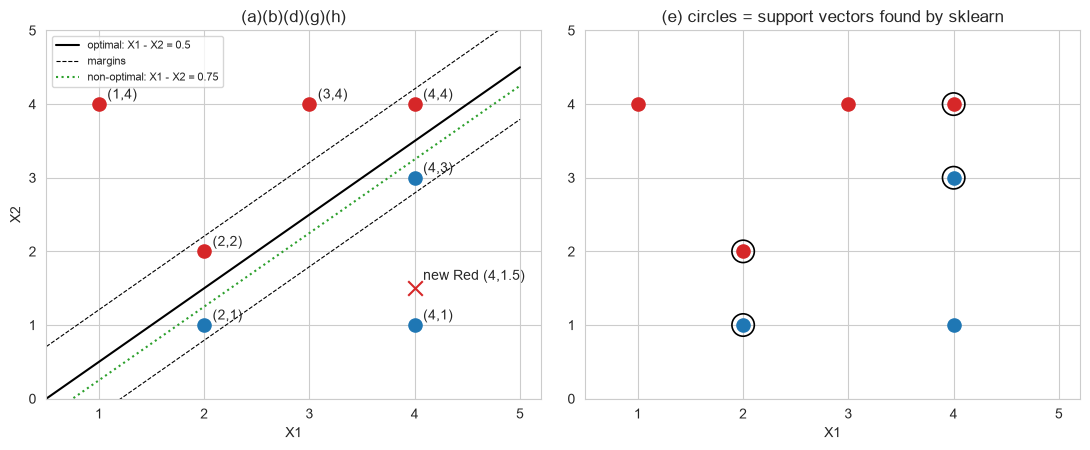

In [18]:
import numpy as np
pts = [(3,4,'R'),(2,2,'R'),(4,4,'R'),(1,4,'R'),(2,1,'B'),(4,3,'B'),(4,1,'B')]
X = np.array([p[:2] for p in pts]); y = np.array([p[2] for p in pts])
colors = {'R': 'tab:red', 'B': 'tab:blue'}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
ax = axes[0]
for (x1, x2, lab) in pts:
    ax.scatter(x1, x2, c=colors[lab], s=90)
    ax.annotate(f'({x1},{x2})', (x1, x2), textcoords='offset points', xytext=(6, 4))
xx = np.linspace(0.5, 5, 10)
ax.plot(xx, xx - 0.5, 'k-', label='optimal: X1 - X2 = 0.5')
ax.plot(xx, xx - 0.5 + 0.5**0.5, 'k--', lw=0.8)
ax.plot(xx, xx - 0.5 - 0.5**0.5, 'k--', lw=0.8, label='margins')
ax.plot(xx, xx - 0.75, color='tab:green', ls=':', label='non-optimal: X1 - X2 = 0.75')
ax.scatter([4], [1.5], marker='x', c='tab:red', s=110)
ax.annotate('new Red (4,1.5)', (4, 1.5), textcoords='offset points', xytext=(6, 6))
ax.set_xlim(0.5, 5.2); ax.set_ylim(0, 5)
ax.set_xlabel('X1'); ax.set_ylabel('X2'); ax.legend(fontsize=8); ax.set_title('(a)(b)(d)(g)(h)')

from sklearn.svm import SVC
m = SVC(kernel='linear', C=1e6).fit(X, y)
print('sklearn SVM: w =', m.coef_.round(4)[0].tolist(), ' b =', round(m.intercept_[0], 4))
print('hyperplane: %.4f*X1 + %.4f*X2 + %.4f = 0  (same line as X1 - X2 = 0.5)'
      % (m.coef_[0][0], m.coef_[0][1], m.intercept_[0]))
print('support vectors:', [tuple(v) for v in m.support_vectors_])
ax = axes[1]
for (x1, x2, lab) in pts:
    ax.scatter(x1, x2, c=colors[lab], s=90)
for v in m.support_vectors_:
    ax.scatter(v[0], v[1], s=260, facecolors='none', edgecolors='k', linewidths=1.2)
ax.set_xlim(0.5, 5.2); ax.set_ylim(0, 5)
ax.set_xlabel('X1'); ax.set_title('(e) circles = support vectors found by sklearn')
plt.tight_layout(); plt.show()

Note on (b): sklearn prints the scaled line $-2X_1 + 2X_2 + 1 = 0$ because
its internal class order puts Blue first; dividing by $-2$ gives
$X_1 - X_2 = 0.5$, identical to the hand-derived hyperplane. The support
vectors it marks are exactly (2,2), (4,4), (2,1), (4,3), as argued in (e).

References for the written questions:

- James, Gareth, Daniela Witten, Robert Tibshirani, and Trevor Hastie.
  *An Introduction to Statistical Learning: with Applications in Python*.
  Springer, 2023. Exercises 6.6.3, 6.6.5, 8.4.5, 9.7.3.
- Chawla, Nitesh V., Kevin W. Bowyer, Lawrence O. Hall, and W. Philip Kegelmeyer.
  "SMOTE: Synthetic Minority Over-sampling Technique." *Journal of Artificial
  Intelligence Research*, vol. 16, 2002, pp. 321-357.